# Week 3 — Pixel RES / NRES / empty (3-class)

Self-contained training notebook:

1. Load empty-aware GT (`datasets/week3_pixel_gt_v2`)
2. **Classifier** — hard labels + SMOTE + CE (LORO)
3. **Regression** — soft GT `frac_res/nres/empty` + ROS (carry soft Y) + softmax MSE + decode (`building_share_max=0.15`)

**Empty rule.** No Track-A footprint overlap → `empty`. Empties are AOI-sampled (`n_empty ≈ n_residential` per metro).

**GPU.** LORO folds are sharded across all visible NVIDIA GPUs (PyTorch linear models). Dataset build uses CPU.

**CLI (preferred for training):** `scripts/train_week3_pixel_3class_loro.py` — same path as this notebook.


## Results (from `outputs/week3_pixel_3class/`)

Classifier: hard labels + SMOTE. Regression: soft `frac_*_full` targets (not one-hots).

Decode: `empty` if `frac_res + frac_nres < building_share_max` (**0.15**, OOF-tuned), else majority(RES, NRES).

| Head | LORO mean macro-F1 | OOF macro-F1 | Empty recall |
|---|---|---|---|
| Classifier | 0.446 ± 0.054 | 0.457 | **0.621** |
| Regression→decode (τ=0.15) | **0.503** ± 0.061 | **0.521** | 0.447 |

Regression wins in **9/10** metros.


{
  "name": "week3_pixel_3class_res_nres_empty_v1",
  "n_gpu": 8,
  "n_pixels": 312086,
  "building_share_max": 0.15,
  "decode": "empty if frac_res+frac_nres < building_share_max else argmax(res,nres)",
  "clf_targets": "hard_label_smote",
  "reg_targets": "soft_frac_res_nres_empty_ros",
  "label_counts": {
    "non_residential": 253321,
    "residential": 29798,
    "empty": 28967
  },
  "clf_loro_macro_f1_mean": 0.4462323300607064,
  "clf_loro_macro_f1_std": 0.05435038356839486,
  "reg_loro_macro_f1_mean": 0.5030133981804403,
  "reg_loro_macro_f1_std": 0.0614860504776796,
  "oof_clf_macro_f1": 0.4572393799964856,
  "oof_reg_macro_f1": 0.5211295030279147,
  "reg_beats_clf_metros": 9,
  "n_metros": 10,
  "artifacts": {
    "oof": "/data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/week3_pixel_3class/oof_predictions.parquet",
    "clf_metrics": "/data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/week3_pixel_3class/loro_clf_metrics.csv",
    "reg_metrics": "/data/users/kv1

**oof_confusion_clf_vs_reg.png**

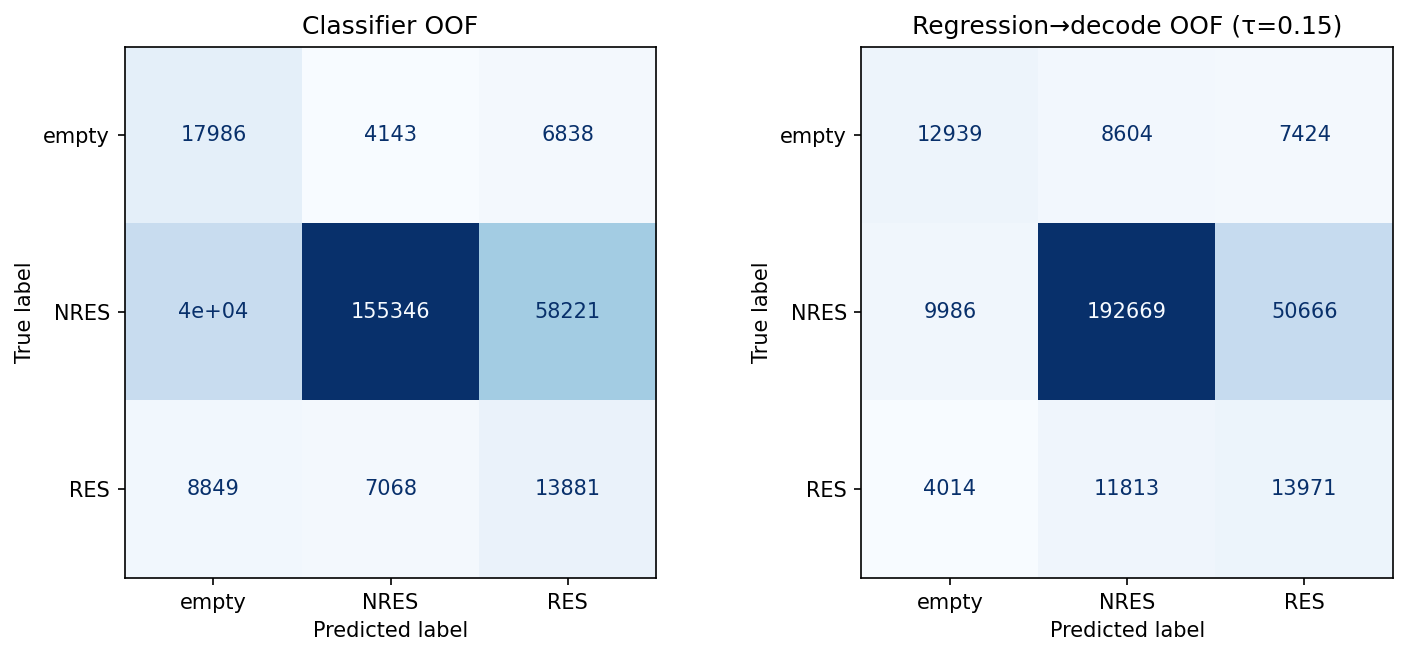

**loro_f1_clf_vs_reg.png**

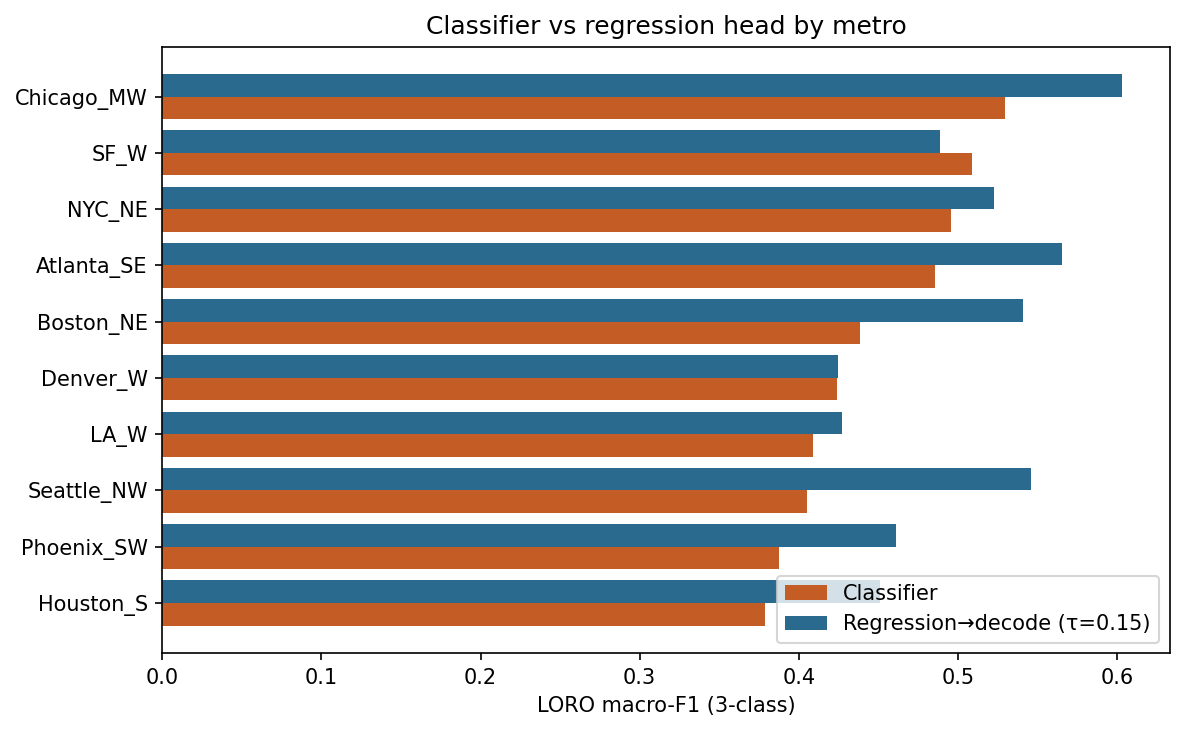

**delta_reg_minus_clf_by_city.png**

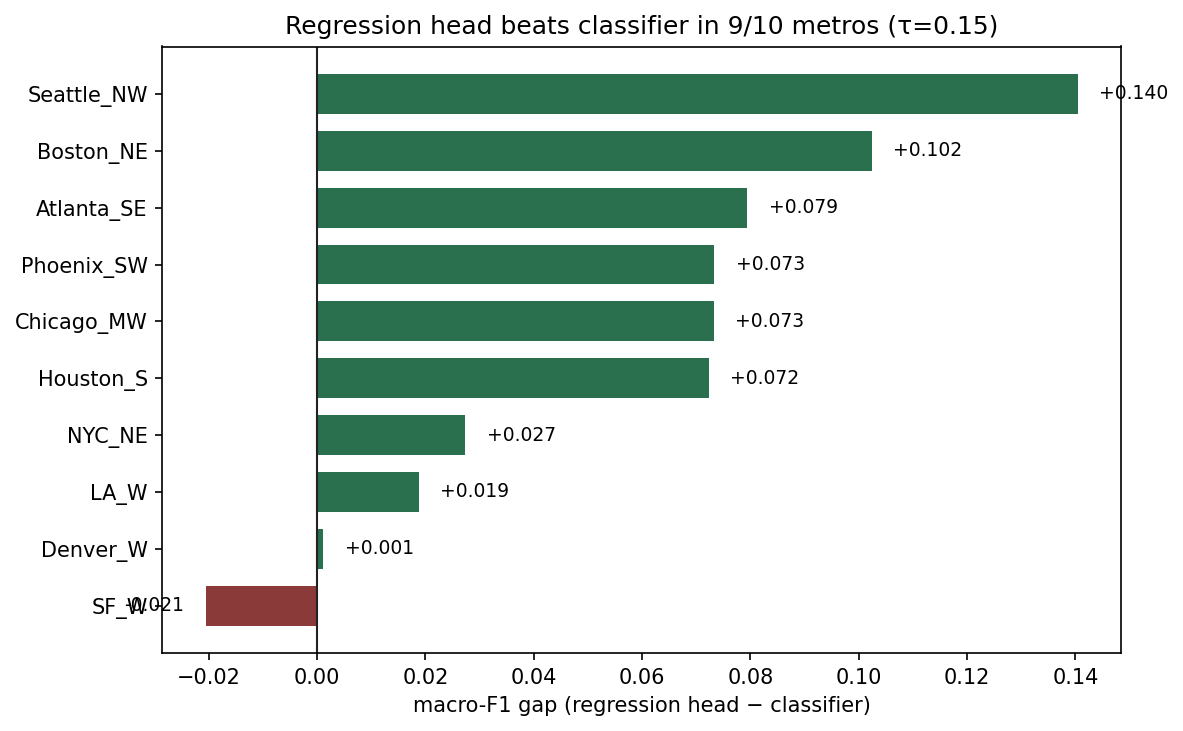

In [1]:
# View cached results without retraining
import json
from IPython.display import Image, Markdown, display
from pathlib import Path
OUT = Path("outputs/week3_pixel_3class")
FIG = OUT / "figures"
print(json.dumps(json.loads((OUT / "summary.json").read_text()), indent=2))
for name in [
    "oof_confusion_clf_vs_reg.png",
    "loro_f1_clf_vs_reg.png",
    "delta_reg_minus_clf_by_city.png",
]:
    p = FIG / name
    if p.exists():
        display(Markdown(f"**{name}**"))
        display(Image(filename=str(p)))


## Mostly-empty band vs Overture (decode-margin sanity check)

GT filter: `frac_res < 10%` ∧ `frac_nres < 10%` ∧ `frac_empty > 90%`.

| | n | share |
|---|---|---|
| **True empty** (zero polygon overlap → ideally 100% FracEmpty) | 28,967 | **42.2%** |
| **Partial footprint** (edge clip → should *not* be 100% empty) | 39,621 | **57.8%** |

A 5–10% “call it empty” rule would wipe out those partial neighbour cells even though they overlap a Track-A polygon. Decode uses **τ=0.15** (OOF-tuned), not 5%.


band n=68,588  ·  true empty 28,967 (42.23%)  ·  partial 39,621 (57.77%)
label counts: {'non_residential': 32786, 'empty': 28967, 'residential': 6831, 'mixed': 4}
partial building share: {'mean': 0.03783934422122622, 'median': 0.03190638760902994, 'p90': 0.08465516887865539, 'max': 0.09999947274730325}


,n,true_empty,partial,pct_true_empty
LA_W,5023.0,1505.0,3518.0,30.0
NYC_NE,8320.0,2708.0,5612.0,32.5
SF_W,4195.0,1384.0,2811.0,33.0
Boston_NE,8658.0,3112.0,5546.0,35.9
Denver_W,6257.0,2751.0,3506.0,44.0
Chicago_MW,6859.0,3068.0,3791.0,44.7
Houston_S,8731.0,4132.0,4599.0,47.3
Phoenix_SW,5942.0,2863.0,3079.0,48.2
Seattle_NW,6607.0,3248.0,3359.0,49.2
Atlanta_SE,7996.0,4196.0,3800.0,52.5


**mostly_empty_band_overture_samples.png**

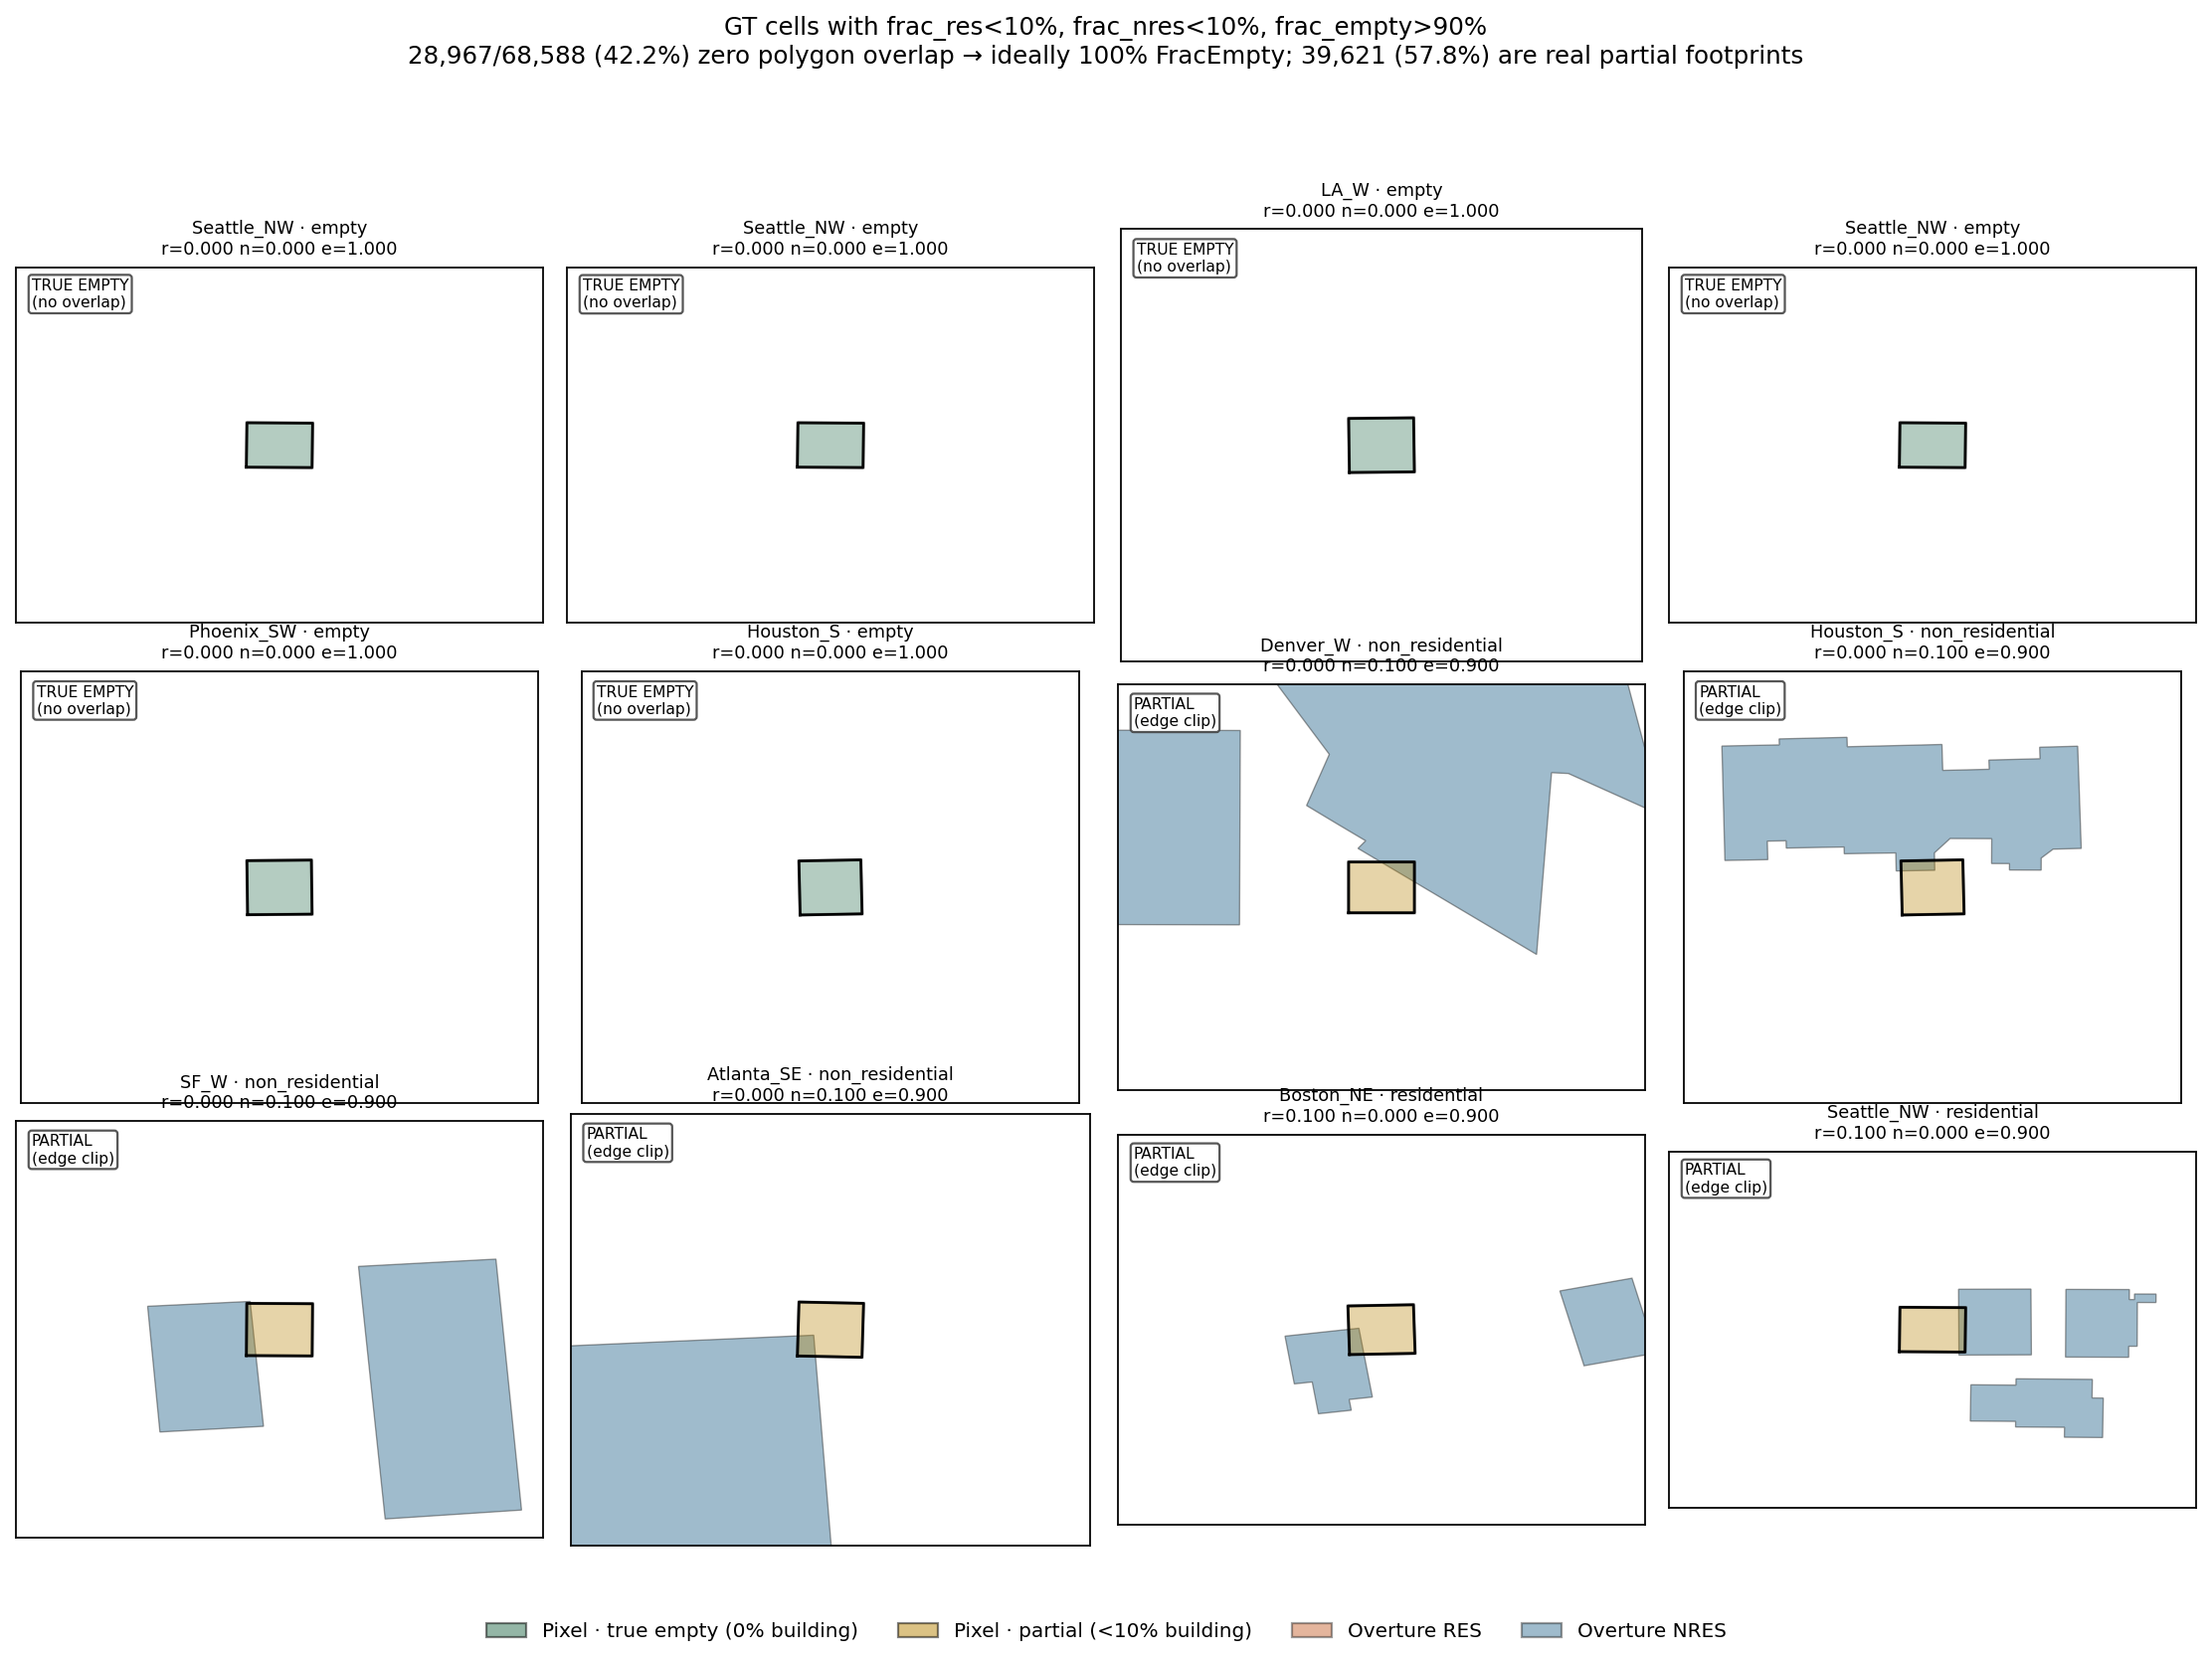

**mostly_empty_band_partial_share_hist.png**

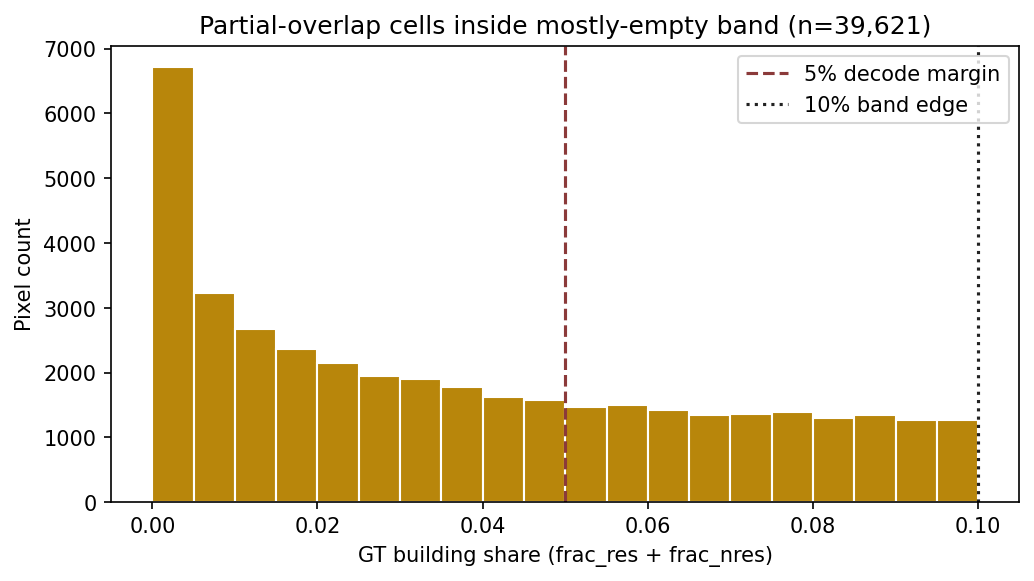

**mostly_empty_band_by_region.png**

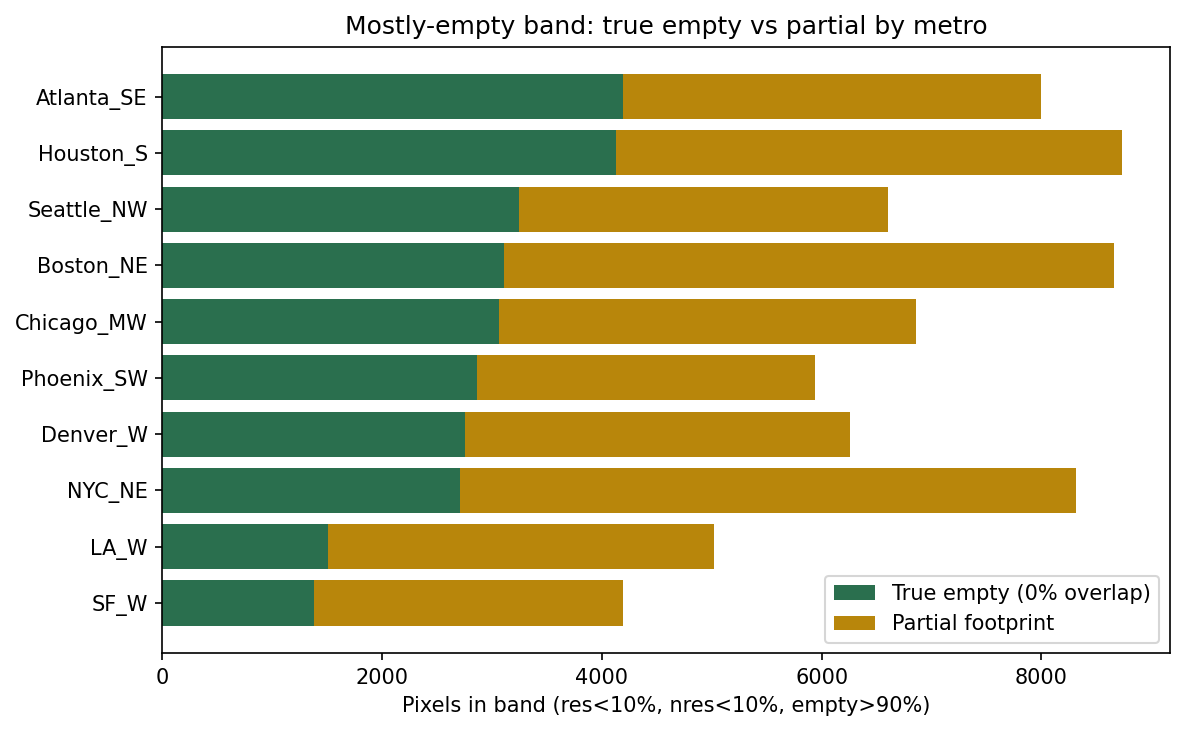

In [2]:
# Build / refresh band analysis + Overture overlays (CPU; ~10s)
import json
import subprocess
import sys
from IPython.display import Image, Markdown, display
from pathlib import Path

import pandas as pd

ROOT = Path(".").resolve()
for _ in range(3):
    if (ROOT / "requirements.txt").exists():
        break
    ROOT = ROOT.parent
OUT = ROOT / "outputs" / "week3_pixel_3class"
FIG = OUT / "figures"
SCRIPT = ROOT / "scripts" / "plot_week3_mostly_empty_band.py"
need = [
    "mostly_empty_band_overture_samples.png",
    "mostly_empty_band_partial_share_hist.png",
    "mostly_empty_band_by_region.png",
    "mostly_empty_band_analysis.json",
]
if not all((FIG / n).exists() if n.endswith(".png") else (OUT / n).exists() for n in need):
    subprocess.check_call([sys.executable, "-u", str(SCRIPT)], cwd=str(ROOT))

analysis = json.loads((OUT / "mostly_empty_band_analysis.json").read_text())
print(
    f"band n={analysis['n_band']:,}  ·  "
    f"true empty {analysis['n_true_empty_zero_overlap']:,} "
    f"({analysis['pct_should_be_100pct_empty']}%)  ·  "
    f"partial {analysis['n_partial_footprint']:,} "
    f"({analysis['pct_should_NOT_be_100pct_empty']}%)"
)
print("label counts:", analysis["label_counts_in_band"])
print("partial building share:", analysis["partial_building_share"])
display(pd.DataFrame(analysis["by_region"]).T.sort_values("pct_true_empty"))

for name in [
    "mostly_empty_band_overture_samples.png",
    "mostly_empty_band_partial_share_hist.png",
    "mostly_empty_band_by_region.png",
]:
    display(Markdown(f"**{name}**"))
    display(Image(filename=str(FIG / name)))


## 0. Setup


In [ ]:
from __future__ import annotations

import json
import multiprocessing as mp
import os
import subprocess
import sys
import warnings
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
# Prefer spawn when available (CUDA-safe). Falls back for notebooks that already forked.
try:
    MP_CTX = mp.get_context("spawn")
except ValueError:
    MP_CTX = None
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.preprocessing import LabelEncoder
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda x: f"{x:0.3f}")

ROOT = Path(".").resolve()
for _ in range(3):
    if (ROOT / "requirements.txt").exists():
        break
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "scripts"))
from week3_pixel_3class_trainlib import (
    BUILDING_SHARE_MAX,
    CLASSES,
    clf_fold_worker,
    decode_fractions,
    reg_fold_worker,
)

PIXELS = ROOT / "datasets" / "week3_pixel_gt_v2" / "pixels.parquet"
BUILDER = ROOT / "scripts" / "build_week3_pixel_gt_with_empty.py"
OUT = ROOT / "outputs" / "week3_pixel_3class"
FIG = OUT / "figures"
CACHE = OUT / "_cache"
BANDS = [f"A{i:02d}" for i in range(64)]

OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)

N_GPU = torch.cuda.device_count() if torch.cuda.is_available() else 0
print(f"ROOT={ROOT}")
print(f"CUDA={torch.cuda.is_available()}  n_gpu={N_GPU}")
for i in range(N_GPU):
    print(f"  cuda:{i}  {torch.cuda.get_device_name(i)}")


## 1. Data


In [ ]:
if not PIXELS.exists():
    print("Building v2 GT…", flush=True)
    subprocess.check_call(
        [
            sys.executable, "-u", str(BUILDER), "--rebuild",
            "--workers", str(min(10, os.cpu_count() or 1)),
        ],
        cwd=str(ROOT),
    )

raw = pd.read_parquet(PIXELS)
print("raw labels:\n", raw["label"].value_counts())
df = raw.loc[raw["label"] != "mixed"].copy().reset_index(drop=True)
assert set(df["label"].unique()) <= {"residential", "non_residential", "empty"}
if "frac_empty_full" not in df.columns:
    df["frac_empty_full"] = np.clip(1.0 - df["frac_res_full"] - df["frac_nres_full"], 0, 1)
if "frac_empty" not in df.columns:
    df["frac_empty"] = np.round(df["frac_empty_full"], 2)

print("train labels (mixed dropped):\n", df["label"].value_counts())
X = df[BANDS].to_numpy(dtype=np.float32)
le = LabelEncoder().fit(CLASSES)
y = le.transform(df["label"].to_numpy())
Y_frac = df[["frac_res_full", "frac_nres_full", "frac_empty_full"]].to_numpy(dtype=np.float32)
regions = df["region"].to_numpy()
region_list = sorted(df["region"].unique().tolist())

np.save(CACHE / "X.npy", X)
np.save(CACHE / "y.npy", y)
np.save(CACHE / "Y_frac.npy", Y_frac)
np.save(CACHE / "regions.npy", regions)
print("n=", len(df), "regions=", region_list)


## 2. Decode head check


In [ ]:
demo = decode_fractions(
    [0, 0.8, 0, 0.4, 0.02, 0.10],
    [0, 0, 0.7, 0.5, 0.02, 0.04],
    [1, 0.2, 0.3, 0.1, 0.96, 0.86],
    building_share_max=BUILDING_SHARE_MAX,  # 0.15
)
# building shares: 0, 0.8, 0.7, 0.9, 0.04, 0.14 → empty / RES / NRES / NRES / empty / empty
assert list(demo) == [
    "empty", "residential", "non_residential", "non_residential", "empty", "empty",
]
print(f"decode ok (building_share_max={BUILDING_SHARE_MAX})", demo)


## 3. Classifier LORO (GPU-sharded)


In [ ]:
x_path, y_path, reg_path = str(CACHE / "X.npy"), str(CACHE / "y.npy"), str(CACHE / "regions.npy")
jobs = []
for i, r in enumerate(region_list):
    jobs.append({
        "te_region": r,
        "x_path": x_path,
        "y_path": y_path,
        "reg_path": reg_path,
        "cache_dir": str(CACHE),
        "gpu_id": (i % N_GPU) if N_GPU else None,
    })

oof_pred = np.full(len(df), -1, dtype=np.int64)
oof_proba = np.full((len(df), 3), np.nan)
clf_rows = []
max_workers = max(1, N_GPU) if N_GPU else min(8, os.cpu_count() or 1)
print(f"clf LORO · {len(jobs)} folds · max_workers={max_workers}", flush=True)

pool_kw = {"max_workers": max_workers}
if MP_CTX is not None:
    pool_kw["mp_context"] = MP_CTX
with ProcessPoolExecutor(**pool_kw) as pool:
    futs = {pool.submit(clf_fold_worker, job): job["te_region"] for job in jobs}
    for fut in tqdm(as_completed(futs), total=len(futs), desc="clf"):
        r = fut.result()
        te = np.load(CACHE / f"clf_idx_{r['region']}.npy")
        oof_pred[te] = np.load(CACHE / f"clf_pred_{r['region']}.npy")
        oof_proba[te] = np.load(CACHE / f"clf_proba_{r['region']}.npy")
        clf_rows.append(r)
        print(
            f"  {r['region']:12s}  F1={r['f1_macro']:.3f}  acc={r['accuracy']:.3f}  "
            f"{r['n_train_before']}→{r['n_train_after_smote']}  [{r['device']}]",
            flush=True,
        )

clf_metrics = pd.DataFrame(clf_rows).sort_values("region").reset_index(drop=True)
clf_metrics.to_csv(OUT / "loro_clf_metrics.csv", index=False)
print("mean macro-F1 clf=", float(clf_metrics["f1_macro"].mean()))
print(classification_report(y, oof_pred, target_names=list(le.classes_), digits=3))


## 4. Regression LORO — soft frac targets + decode (GPU-sharded)


In [ ]:
# Targets = GT frac_res_full / frac_nres_full / frac_empty_full (not hard one-hots).
# Class balance via RandomOverSampler on hard labels, carrying soft Y with each row.
yf_path = str(CACHE / "Y_frac.npy")
jobs = []
for i, r in enumerate(region_list):
    jobs.append({
        "te_region": r,
        "x_path": x_path,
        "y_path": y_path,
        "yf_path": yf_path,
        "reg_path": reg_path,
        "cache_dir": str(CACHE),
        "gpu_id": (i % N_GPU) if N_GPU else None,
    })

oof_frac = np.full((len(df), 3), np.nan)
reg_rows = []
print(f"reg LORO · {len(jobs)} folds · max_workers={max_workers}", flush=True)

with ProcessPoolExecutor(**pool_kw) as pool:
    futs = {pool.submit(reg_fold_worker, job): job["te_region"] for job in jobs}
    for fut in tqdm(as_completed(futs), total=len(futs), desc="reg"):
        r = fut.result()
        te = np.load(CACHE / f"reg_idx_{r['region']}.npy")
        oof_frac[te] = np.load(CACHE / f"reg_pred_{r['region']}.npy")
        reg_rows.append(r)
        print(
            f"  {r['region']:12s}  F1={r['f1_macro']:.3f}  "
            f"MAE={r['mae_res']:.3f}/{r['mae_nres']:.3f}/{r['mae_empty']:.3f}  [{r['device']}]",
            flush=True,
        )

reg_metrics = pd.DataFrame(reg_rows).sort_values("region").reset_index(drop=True)
reg_metrics.to_csv(OUT / "loro_reg_metrics.csv", index=False)
decoded = decode_fractions(
    oof_frac[:, 0], oof_frac[:, 1], oof_frac[:, 2],
    building_share_max=BUILDING_SHARE_MAX,
)
class_to_i = {c: i for i, c in enumerate(le.classes_)}
oof_reg_pred = np.array([class_to_i[s] for s in decoded], dtype=np.int64)
print("mean macro-F1 reg-head=", float(reg_metrics["f1_macro"].mean()))
print(classification_report(y, oof_reg_pred, target_names=list(le.classes_), digits=3))


## 5. Save artifacts + plots


In [ ]:
oof = df[["pixel_id", "region", "label", "pixel_lon", "pixel_lat",
          "frac_res", "frac_nres", "frac_empty"]].copy()
oof["y"] = y
oof["y_pred_clf"] = oof_pred
oof["y_pred_reg"] = oof_reg_pred
oof["pred_label_clf"] = le.inverse_transform(oof_pred)
oof["pred_label_reg"] = decoded
oof["pred_frac_res"] = np.round(oof_frac[:, 0], 2)
oof["pred_frac_nres"] = np.round(oof_frac[:, 1], 2)
oof["pred_frac_empty"] = np.round(oof_frac[:, 2], 2)
oof.to_parquet(OUT / "oof_predictions.parquet", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, pred, title in [
    (axes[0], oof_pred, "Classifier OOF"),
    (axes[1], oof_reg_pred, "Regression→decode OOF"),
]:
    ConfusionMatrixDisplay.from_predictions(
        y, pred, display_labels=["empty", "NRES", "RES"], cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title(title)
fig.tight_layout()
fig.savefig(FIG / "oof_confusion_clf_vs_reg.png", dpi=150, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(FIG / "oof_confusion_clf_vs_reg.png")))

m = clf_metrics.merge(
    reg_metrics[["region", "f1_macro"]], on="region", suffixes=("_clf", "_reg")
).sort_values("f1_macro_clf")
fig, ax = plt.subplots(figsize=(8, 5))
ypos = np.arange(len(m))
ax.barh(ypos - 0.2, m["f1_macro_clf"], 0.4, label="Classifier", color="#c45c26")
ax.barh(ypos + 0.2, m["f1_macro_reg"], 0.4, label="Regression→decode", color="#2b6a8f")
ax.set_yticks(ypos)
ax.set_yticklabels(m["region"])
ax.set_xlabel("LORO macro-F1 (3-class)")
ax.set_title("Classifier vs regression head by metro")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "loro_f1_clf_vs_reg.png", dpi=150, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(FIG / "loro_f1_clf_vs_reg.png")))

m = m.copy()
m["delta"] = m["f1_macro_reg"] - m["f1_macro_clf"]
m = m.sort_values("delta")
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#2a6f4e" if v >= 0 else "#8b3a3a" for v in m["delta"]]
bars = ax.barh(m["region"], m["delta"], color=colors, height=0.7)
ax.axvline(0, color="#222", lw=1)
ax.set_xlabel("macro-F1 gap (regression head − classifier)")
n_win = int((m["delta"] >= 0).sum())
ax.set_title(f"Regression head beats classifier in {n_win}/{len(m)} metros")
for bar, v in zip(bars, m["delta"]):
    ax.text(
        v + (0.004 if v >= 0 else -0.004),
        bar.get_y() + bar.get_height() / 2,
        f"{v:+.3f}",
        va="center",
        ha="left" if v >= 0 else "right",
        fontsize=9,
    )
ax.tick_params(axis="y", pad=8, length=0)
fig.tight_layout()
fig.savefig(FIG / "delta_reg_minus_clf_by_city.png", dpi=150, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(FIG / "delta_reg_minus_clf_by_city.png")))

summary = {
    "name": "week3_pixel_3class_res_nres_empty_v1",
    "features": BANDS,
    "classes": list(le.classes_),
    "protocol": "leave-one-region-out",
    "building_share_max": BUILDING_SHARE_MAX,
    "decode": "empty if frac_res+frac_nres < building_share_max else argmax(res,nres)",
    "n_gpu": N_GPU,
    "n_pixels": int(len(df)),
    "label_counts": {k: int(v) for k, v in df["label"].value_counts().items()},
    "clf_loro_macro_f1_mean": float(clf_metrics["f1_macro"].mean()),
    "clf_loro_macro_f1_std": float(clf_metrics["f1_macro"].std(ddof=1)),
    "reg_loro_macro_f1_mean": float(reg_metrics["f1_macro"].mean()),
    "reg_loro_macro_f1_std": float(reg_metrics["f1_macro"].std(ddof=1)),
    "oof_clf_macro_f1": float(f1_score(y, oof_pred, average="macro", zero_division=0)),
    "oof_reg_macro_f1": float(f1_score(y, oof_reg_pred, average="macro", zero_division=0)),
    "paths": {
        "pixels": str(PIXELS.relative_to(ROOT)),
        "oof": "outputs/week3_pixel_3class/oof_predictions.parquet",
        "figures": "outputs/week3_pixel_3class/figures",
    },
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2) + "
")
print(json.dumps({k: summary[k] for k in summary if "f1" in k or k in ("n_gpu", "n_pixels", "label_counts")}, indent=2))
print("Wrote", OUT)
